Projection maps showing the multi-model mean change per degree of global warming, with stippling to indicate the level of model agreement on the direction of change. Based on Figure 3 of [Fischer et al 2014](https://doi.org/10.1002/2014GL062018).

In [1]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import cartopy
import cartopy.crs as ccrs
import cmocean

In [15]:
west_lon = 100
east_lon = 190
south_lat = -50
north_lat = 0

In [24]:
# TODO: This could be a YAML file

cmip7_files = {}
cmip7_files['pr'] = {}
cmip7_files['pr']['UKCM2a-0-HH'] = {}
cmip7_files['pr']['UKCM2a-0-HH']['r1i1p1f1'] = [
    'pr_tavg-u-hxy-u_mon_glb_gr1.5_UKCM2a-0-HH_historical_r1i1p1f1_185001-202212.nc',
    'pr_tavg-u-hxy-u_mon_glb_gr1.5_UKCM2a-0-HH_scen7-h_r1i1p1f1_202201-210012.nc',
]
cmip7_files['pr']['UKCM2a-0-HH']['r2i1p1f1'] = [
    'pr_tavg-u-hxy-u_mon_glb_gr1.5_UKCM2a-0-HH_historical_r2i1p1f1_185001-202112.nc',
    'pr_tavg-u-hxy-u_mon_glb_gr1.5_UKCM2a-0-HH_scen7-h_r2i1p1f1_202201-210012.nc',
]

cmip7_files['tas'] = {}
cmip7_files['tas']['UKCM2a-0-HH'] = {}
cmip7_files['tas']['UKCM2a-0-HH']['r1i1p1f1'] = [
    'tas_tavg-h2m-hxy-u_mon_glb_gr1.5_UKCM2a-0-HH_historical_r1i1p1f1_185001-202212.nc',
    'tas_tavg-h2m-hxy-u_mon_glb_gr1.5_UKCM2a-0-HH_scen7-h_r1i1p1f1_202201-210012.nc'
]
cmip7_files['tas']['UKCM2a-0-HH']['r2i1p1f1'] = [
    'tas_tavg-h2m-hxy-u_mon_glb_gr1.5_UKCM2a-0-HH_historical_r2i1p1f1_185001-202112.nc',
    'tas_tavg-h2m-hxy-u_mon_glb_gr1.5_UKCM2a-0-HH_scen7-h_r2i1p1f1_202201-210012.nc',
]     

## Read precipitation data

In [25]:
def annual_aggregation(da):
    """Annual aggregation of monthly data"""

    da_annual = da.resample(time='YE-DEC').sum(dim='time', min_count=12, keep_attrs=True)
    years = da_annual.time.dt.year
    da_annual = da_annual.assign_coords(year=years).swap_dims({"time": "year"}).drop_vars("time")
    da_annual['season'] = 'Annual'

    return da_annual


def seasonal_aggregation(da):
    """Seasonal aggregation of monthly data"""

    da_seasonal = da.resample(time='QE-NOV').sum(dim='time', min_count=3, keep_attrs=True)    
    months = da_seasonal.time.dt.month
    da_out_dict = {}
    da_out_dict['DJF'] = da_seasonal.sel({'time': months.isin([2])}).isel(time=slice(0, -1))
    da_out_dict['MAM'] = da_seasonal.sel({'time': months.isin([5])})
    da_out_dict['JJA'] = da_seasonal.sel({'time': months.isin([8])})
    da_out_dict['SON'] = da_seasonal.sel({'time': months.isin([11])})
    da_out_list = []
    for season, da_out in da_out_dict.items():
        years = da_out.time.dt.year
        da_out = da_out.assign_coords(year=years).swap_dims({"time": "year"}).drop_vars("time")
        da_out['season'] = season
        da_out_list.append(da_out)

    return da_out_list


def temporal_aggregation(model, run):
    """Read and temporally aggregate precipitation data"""
    
    infiles = cmip7_files['pr'][model][run]
    ds = xr.open_mfdataset(infiles, combine="nested", concat_dim="time")
    ds = ds.drop_duplicates(dim="time")
    ds['pr'] = ds['pr'] * 86400
    ds['pr'] = ds['pr'] * ds.time.dt.days_in_month
    ds['pr'].attrs['units'] = 'mm'

    da_annual = annual_aggregation(ds['pr'])
    da_seasonal_list = seasonal_aggregation(ds['pr'])
    da_aggregation = xr.concat([da_annual] + da_seasonal_list, dim='season')
    
    return da_aggregation

In [26]:
da_pr_r1 = temporal_aggregation('UKCM2a-0-HH', 'r1i1p1f1')
da_pr_r1 = da_pr_r1.compute()

In [27]:
da_pr_ave_r1 = da_pr_r1.mean(dim='year', keep_attrs=True)

In [28]:
da_pr_r2 = temporal_aggregation('UKCM2a-0-HH', 'r2i1p1f1')
da_pr_r2 = da_pr_r2.compute()

In [29]:
da_pr_ave_r2 = da_pr_r2.mean(dim='year', keep_attrs=True)

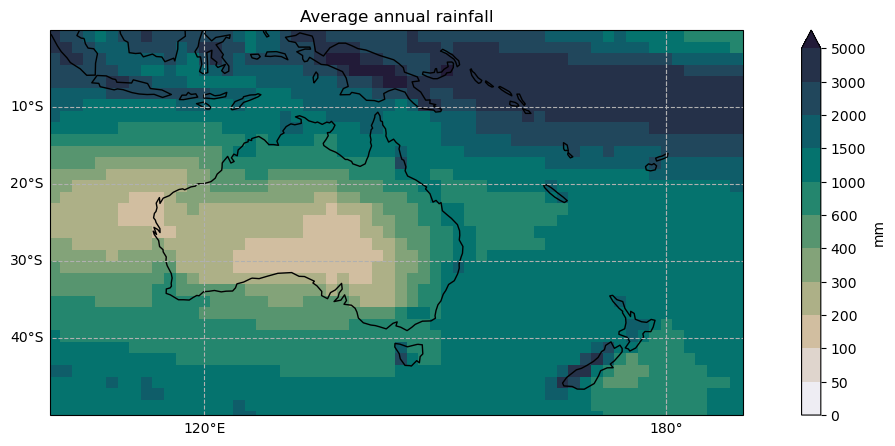

In [30]:
fig = plt.figure(figsize=[15, 5])

ax1 = fig.add_subplot(111, projection=ccrs.PlateCarree(central_longitude=180))

levels = [0, 50, 100, 200, 300, 400, 600, 1000, 1500, 2000, 3000, 5000]
plot1 = da_pr_ave_r1.sel({'season': 'Annual'}).plot(
    ax=ax1,
    transform=ccrs.PlateCarree(),
    levels=levels,
    extend='max',
    cmap=cmocean.cm.rain,
    cbar_kwargs={'label': 'mm'},
)
cbar1 = plot1.colorbar
cbar1.set_ticks(levels, labels=levels)
ax1.set_extent((west_lon, east_lon, south_lat, north_lat), crs=ccrs.PlateCarree())
ax1.coastlines()
ax1.add_feature(cartopy.feature.STATES)
gls1 = ax1.gridlines(linestyle="--", draw_labels=True)
gls1.top_labels = False
gls1.right_labels = False
ax1.tick_params(axis='y', labelleft=False)
ax1.set_title('Average annual rainfall')
plt.show()

## Read temperature data

In [31]:
def calc_annual_gmst(model, run):
    """Read surface temperature data and calculate annual global mean surface temperature timeseries"""

    infiles = cmip7_files['tas'][model][run]
    ds = xr.open_mfdataset(infiles, combine="nested", concat_dim="time")
    ds = ds.drop_duplicates(dim="time")

    spatial_weights = np.cos(np.deg2rad(ds['lat']))
    gmst = ds['tas'].weighted(spatial_weights).mean(dim=('lat', 'lon'), keep_attrs=True)

    days_in_month = gmst['time'].dt.days_in_month
    temporal_weights = (
        days_in_month.groupby('time.year') / days_in_month.groupby('time.year').sum()
    )
    annual_gmst = (gmst * temporal_weights).groupby('time.year').sum(dim='time', keep_attrs=True)

    annual_gmst.name = 'gmst'

    return annual_gmst

In [32]:
annual_gmst_r1 = calc_annual_gmst('UKCM2a-0-HH', 'r1i1p1f1')
annual_gmst_r1 = annual_gmst_r1.compute()

In [33]:
annual_gmst_r2 = calc_annual_gmst('UKCM2a-0-HH', 'r2i1p1f1')
annual_gmst_r2 = annual_gmst_r2.compute()

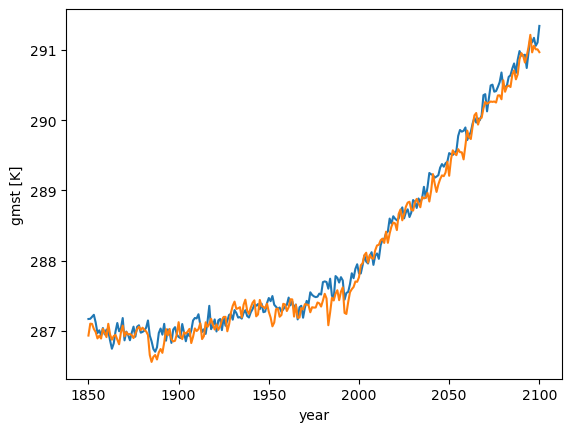

In [34]:
annual_gmst_r1.plot()
annual_gmst_r2.plot()

## Linear regression - precipitation vs GMST

In [35]:
pr_vs_gmst_r1 = da_pr_r1.assign_coords(gmst=('year', annual_gmst_r1.data)).swap_dims({'year': 'gmst'})

In [36]:
pr_vs_gmst_r2 = da_pr_r2.assign_coords(gmst=('year', annual_gmst_r2.data)).swap_dims({'year': 'gmst'})

In [39]:
pr_vs_gmst = xr.concat([pr_vs_gmst_r1, pr_vs_gmst_r2], dim="gmst")

In [40]:
fit = pr_vs_gmst.polyfit(dim='gmst', deg=1)

In [41]:
slope = fit.polyfit_coefficients.sel(degree=1)
intercept = fit.polyfit_coefficients.sel(degree=0)

In [45]:
## FIXME: Needs to be pr_ave over both runs

slope_pct = (slope / da_pr_ave_r1) * 100

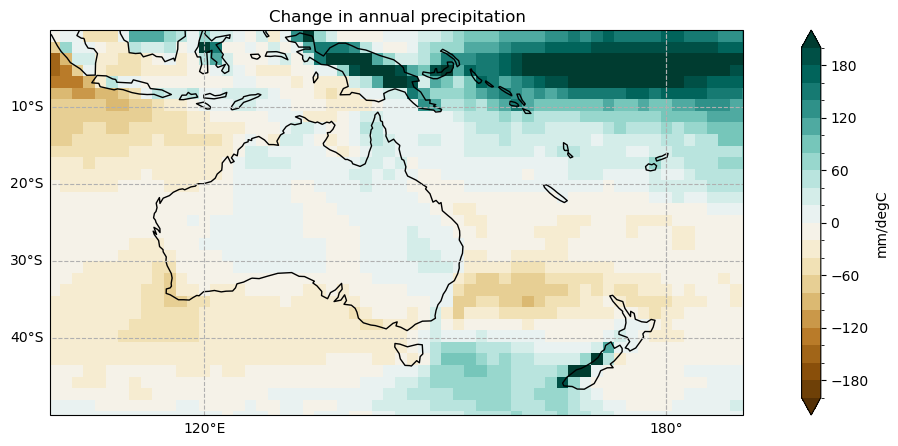

In [46]:
fig = plt.figure(figsize=[15, 5])

ax1 = fig.add_subplot(111, projection=ccrs.PlateCarree(central_longitude=180))
slope.sel({'season': 'Annual'}).plot(
    ax=ax1,
    transform=ccrs.PlateCarree(),
    levels=np.arange(-200, 201, 20),
    extend='both',
    cmap='BrBG',
    cbar_kwargs={'label': 'mm/degC'},
)
ax1.coastlines()
#ax1.add_feature(cartopy.feature.STATES)
gls1 = ax1.gridlines(linestyle="--", draw_labels=True)
gls1.top_labels = False
gls1.right_labels = False
ax1.tick_params(axis='y', labelleft=False)
ax1.set_extent((west_lon, east_lon, south_lat, north_lat), crs=ccrs.PlateCarree())
ax1.set_title('Change in annual precipitation')

plt.show()

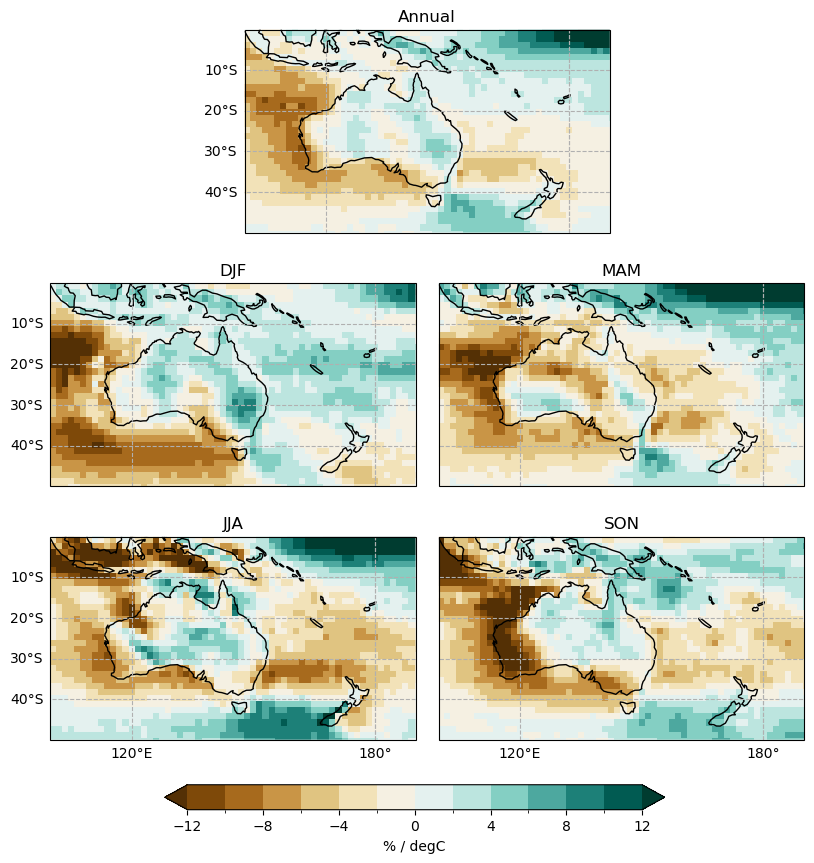

In [47]:
fig = plt.figure(figsize=[10, 10])
gs = gridspec.GridSpec(3, 4, wspace=0.01, hspace=0.25)
ax_dict = {
    'Annual': plt.subplot(gs.new_subplotspec((0, 1), colspan=2), projection=ccrs.PlateCarree(central_longitude=180)),
    'DJF': plt.subplot(gs.new_subplotspec((1, 0), colspan=2), projection=ccrs.PlateCarree(central_longitude=180)),
    'MAM': plt.subplot(gs.new_subplotspec((1, 2), colspan=2), projection=ccrs.PlateCarree(central_longitude=180)),
    'JJA': plt.subplot(gs.new_subplotspec((2, 0), colspan=2), projection=ccrs.PlateCarree(central_longitude=180)),
    'SON': plt.subplot(gs.new_subplotspec((2, 2), colspan=2), projection=ccrs.PlateCarree(central_longitude=180)),
}
for season, ax in ax_dict.items():
    im = slope_pct.sel({'season': season}).plot(
        ax=ax,
        transform=ccrs.PlateCarree(),
        levels=np.arange(-12, 12.1, 2),
        extend='both',
        cmap='BrBG',
        add_colorbar=False,
    )
    ax.set_title(season)
    ax.coastlines()
    ax.set_extent((west_lon, east_lon, south_lat, north_lat), crs=ccrs.PlateCarree())
    gls = ax.gridlines(linestyle="--", draw_labels=True)
    gls.top_labels = False
    gls.right_labels = False
    if season in ['MAM', 'SON']:
        gls.left_labels = False
    if season in ['Annual', 'DJF', 'MAM']:
        gls.bottom_labels = False

span = 0.5
left = (1 - span) / 2.0
bottom = 0.1
width = span
height = 0.025
fig.subplots_adjust(bottom=0.17)
cbar_ax = fig.add_axes([left, bottom, width, height])
fig.colorbar(im, cax=cbar_ax, orientation='horizontal', label= '% / degC')

plt.show()